# 學生學習與作業版｜任務 6：相關係數與散布圖

**姓名：** 王翊綺　**學號／組別：** C114118117　**完成日期：** 11/19

**學習目標：** 檢查有效配對，以散布圖與相關係數描述線性關係，區分相關與因果。

本單元與教師版「任務 6」相同標題、資料、教學順序與範例；除了明確標示的作業與填空，其餘教師版教材內容保留。對照重點：程式填空對應教師版「6.1 配對」。

### 如何完成
1. 先閱讀觀念與執行資料準備；各單元可以獨立啟動，不需要依賴上一單元的變數。
2. **💻 P 作業**：在指定程式 cell 補上 `____`，可先用提供的 Vibe Coding 提示詞詢問 AI。補完再執行，並執行後面的驗證 cell。未填時出現 `NameError` 是預期現象，先完成填空再繼續。
3. **📝 Q 作業**：查詢 AI、比較教材內容，填寫緊接的文字作答區；請記錄實際提示詞、自己的解釋與查證方式。
4. **🎯 M 小任務**：在任務 4、8、12、16 將前面幾單元整合成可執行的成果。不要只交 AI 回覆，要交實際程式、輸出與自己的解釋。
5. 把 Notebook 存到自己的 Google 雲端硬碟，完成後下載／依教師指示繳交 `.ipynb`；小任務保留輸出、文字與 AI 使用紀錄。

**案例限制：**本資料是公式生成的 60 筆模擬紀錄，不能推論真實學生或因果。缺失與 15 小時值在計分後加入。預測時欄位可得性是假設；全部資料已在前半段探索，後續切出的測試集僅示範流程，不能視為完全獨立的新資料。

**完成檢核：**本單元有 1 項程式填空、2 項 AI 查詢作答；若是任務 4、8、12、16，另外有 1 項整合小任務。請保留自己的輸出、回答和驗證紀錄。


## 共用資料準備
以下在記憶體重建與既有教材相同的資料。執行後可以直接開始本單元；不會覆寫 CSV。


In [1]:
# 匯入套件：numpy 建立隨機資料，pandas 管理表格，pyplot 繪圖
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 固定種子，並維持呼叫順序，以重現原教材的 60 筆模擬資料
rng = np.random.default_rng(42)
n = 60
departments = ["資訊管理", "企業管理", "金融管理"]
# 每個字典鍵是一個欄位；對應的值是 60 名學生的資料
data = {
    "student_id": range(1, n + 1),
    "department": rng.choice(departments, n),
    "sleep_hours": rng.normal(6.7, 1.1, n).round(1),
    "screen_time_hours": rng.normal(5.0, 1.5, n).clip(1, 10).round(1),
    "study_hours": rng.normal(2.5, 1.0, n).clip(0.5, 6).round(1),
    "attendance_rate": rng.normal(88, 8, n).clip(60, 100).round(0),
}
df = pd.DataFrame(data)
# 成績依設定公式與隨機誤差建立；關係來自模擬規則，不能視為因果發現
noise = rng.normal(0, 5, n)
score = (50 + 3 * df["study_hours"] + 2 * df["sleep_hours"]
         - 1.2 * df["screen_time_hours"] + 0.15 * df["attendance_rate"] + noise)
df["quiz_score"] = score.clip(0, 100).round(0)
# 故意在計分後加入資料品質問題；無法從表格還原計分時原始值
df.loc[[5, 17], "sleep_hours"] = np.nan
df.loc[8, "screen_time_hours"] = 15.0
print("模擬資料形狀（列, 欄）：", df.shape)


模擬資料形狀（列, 欄）： (60, 7)


## 6.1 配對與散布圖
散布圖每點是一筆紀錄。先確認兩欄都有效，再觀察方向、形狀和極端點；成績生成公式已使用讀書時間。

## 💻 學生作業 06-P1｜Vibe Coding 程式填空
**對應教師版：**任務 6「6.1 配對」的示範程式。

**任務：**只保留 study_hours 和 quiz_score 都不是缺失值的列，另存 pairs，後續會畫散布圖。

**執行方式：**找到下一個程式儲存格中的 `____`，使用自己撰寫或 AI 建議的程式補齊，保留其他已提供的程式與註解。補完後先執行該 cell，再執行緊接的自動檢查；後續單元內容可能依賴此變數。

**可使用的 Vibe Coding 提示詞：**
```text
我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：只保留 study_hours 和 quiz_score 都不是缺失值的列，另存 pairs，後續會畫散布圖。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。
```
完成後記錄實際使用的提示詞與自己改動的地方。


有效配對筆數： 60


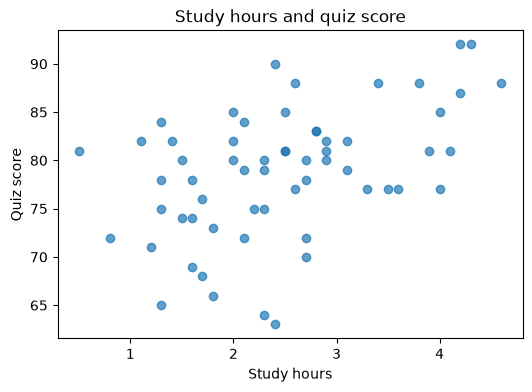

In [2]:
# subset 指定配對欄位；只建立分析副本，保留 df
pairs = df.dropna(subset=["study_hours", "quiz_score"])[["study_hours", "quiz_score"]].copy()
# TODO：建立兩欄皆有效的資料副本
print("有效配對筆數：", len(pairs))
plt.figure(figsize=(6, 4))
plt.scatter(pairs["study_hours"], pairs["quiz_score"], alpha=0.7)
plt.xlabel("Study hours"); plt.ylabel("Quiz score")
plt.title("Study hours and quiz score"); plt.show()


### ✅ 作業 06-P1｜執行驗證
執行下方程式，並同時檢查上方實際輸出。自動檢查只涵蓋主要條件；如果圖表、說明或資料來源不符任務，仍需人工修正。


In [3]:
assert pairs[["study_hours", "quiz_score"]].notna().all().all()
assert len(pairs) == len(df.dropna(subset=["study_hours", "quiz_score"]))
print("檢查通過：有效配對筆數正確。")


檢查通過：有效配對筆數正確。


### ✍️ 作業 06-P1｜我的完成紀錄
- 我實際使用的提示詞（若未使用 AI 請註明）：
使用上下段程式 + 我是 Python 與資料分析初學者，正在 Google Colab 使用 pandas、numpy、matplotlib 或 scikit-learn。
我的任務是：只保留 study_hours 和 quiz_score 都不是缺失值的列，另存 pairs，後續會畫散布圖。
請依我貼上的上下文，只協助補上 ____，保留指定變數名稱與後續程式，不修改原始 df。
請解釋每一步的作用，提供繁體中文註解及可手動驗證的方法。
不要虛構執行結果；如需額外資訊，先指出缺少什麼。

- 我補上的程式在做什麼：
df.dropna(subset=["study_hours", "quiz_score"])是只在「這兩欄」有缺失時才丟掉該列；其他欄位（例如 sleep_hours）有 NaN 也不會被影響。dropna() 預設回傳新 DataFrame，不碰 df。[["study_hours", "quiz_score"]]用欄位清單只留下散布圖需要的兩欄，讓 pairs 是乾淨的分析副本（後續若新增欄位，也不會牽動原始表）。.copy()明確產生一份實體副本，避免之後對 pairs 動手時出現 SettingWithCopyWarning，也確保 pairs 與 df 不再共享記憶體。

- 執行或驗證遇到的問題與修正：無

- 檢查結果及我如何確認：(用以下的程式做確認)


In [4]:
print(pairs.shape)                 # 預設回傳 (筆數, 2)
print(pairs.columns.tolist())      # 應為 ['study_hours', 'quiz_score']
print(pairs.isna().sum())          # 兩欄都應為 0

len(pairs) == len(df) - df[["study_hours", "quiz_score"]].isna().any(axis=1).sum()

df.isna().sum()           # 執行前後的結果應完全相同
df.shape                    # 仍是你上方 print 出的原始列數
pairs is df                 # 應為 False

pairs.head().merge(df, on=["study_hours", "quiz_score"], how="left").notna().all().all()
df.head(1)[["study_hours", "quiz_score"]]
pairs.head(1)               # 兩個數字應一模一樣

len(df.dropna())            # 沒給 subset：連 sleep_hours 缺值的列也會被刪
len(pairs)                  # 有 subset：只看我們關心的兩欄

(60, 2)
['study_hours', 'quiz_score']
study_hours    0
quiz_score     0
dtype: int64


60

## 📝 學生作業 06-Q1｜AI 查詢與作答：相關與因果
**任務：**Pearson 相關係數接近 0，是否代表完全沒有任何關係？為什麼？

**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。用例子說明 Pearson 係數的方向、線性關係與不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 06-Q1 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：kklc；我是 Python 與資料分析初學者。用例子說明 Pearson 係數的方向、線性關係與不能直接推論因果。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。

- AI 回答重點（請自行整理）：Pearson 相關係數 r 的範圍是 -1 到 1：符號代表方向（正號是同步增減、負號是一個增另一個減），數值大小代表點貼近直線的程度，越接近 ±1 表示線性關係越明確。

- 我的理解與具體例子：相關係數介於-1到1之間，而正負號表方向，但相關再強也不能直接推論因果，因為可能只是混淆變數。(例子如下)

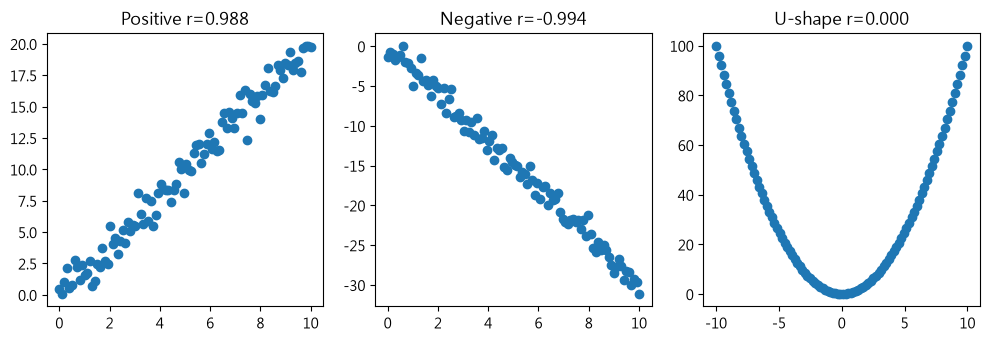

=== 畫圖這段已執行到底；r 值: 0.988 -0.994 0.0


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

for p in [r"C:\Windows\Fonts\msjh.ttc", r"C:\Windows\Fonts\msyh.ttc"]:
    try:
        font_manager.fontManager.addfont(p)
    except Exception:
        pass
plt.rcParams["font.sans-serif"] = ["Microsoft JhengHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

np.random.seed(42)
n = 100

x = np.linspace(0, 10, n)
y_pos = 2 * x + np.random.normal(0, 1, n)
y_neg = -3 * x + np.random.normal(0, 1, n)
x2 = np.linspace(-10, 10, n)
y_curve = x2 ** 2

r_pos   = np.corrcoef(x, y_pos)[0, 1]
r_neg   = np.corrcoef(x, y_neg)[0, 1]
r_curve = np.corrcoef(x2, y_curve)[0, 1]

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].scatter(x, y_pos);    axes[0].set_title(f"Positive r={r_pos:.3f}")
axes[1].scatter(x, y_neg);    axes[1].set_title(f"Negative r={r_neg:.3f}")
axes[2].scatter(x2, y_curve); axes[2].set_title(f"U-shape r={r_curve:.3f}")
fig.tight_layout()

plt.savefig("scatter_demo.png", dpi=110)   # 先確定檔案存得出來
plt.show()

print("=== 畫圖這段已執行到底；r 值:",
      round(r_pos, 3), round(r_neg, 3), round(r_curve, 3))

In [7]:
import matplotlib.pyplot as plt
print(plt.get_backend())

module://matplotlib_inline.backend_inline


- 查證來源／方式及日期（無法查證請註明）：Pearson 相關係數僅衡量線性關聯，r≈0 不能推論變數無關。
  查詢日期：2026/11/19
  來源：統計教材與公開統計教學頁面
- 我檢查或修正 AI 回答的地方：上面例子中錶頭本來是中文，但可能是受到限制會有錯誤，所以改成英文。

## 6.2 Pearson 相關係數
介於 -1 至 1，正負表示線性方向；接近 0 並不代表一定完全沒有非線性關係，也不能證明因果。


In [11]:
# corr 自動以成對非缺失值計算；額外顯示有效筆數比較透明
for field in ["study_hours", "sleep_hours", "screen_time_hours"]:
    valid = df.dropna(subset=[field, "quiz_score"])
    corr = valid[field].corr(valid["quiz_score"])
    print(field, "配對數：", len(valid), "相關係數：", round(corr, 3))


study_hours 配對數： 60 相關係數： 0.471
sleep_hours 配對數： 58 相關係數： -0.015
screen_time_hours 配對數： 60 相關係數： -0.364


## 📝 學生作業 06-Q2｜AI 查詢與作答：有效配對
**任務：**睡眠有缺失時，分析睡眠與成績為何要先確認有效配對數？

A：因為 Pearson 相關是「成對」統計量：每一筆資料必須同時有睡眠與成績才算一組。


**可使用的 AI 提示詞：**
```text
我是 Python 與資料分析初學者。請以一個欄位有缺失的配對資料說明相關分析的有效配對數及偏差風險。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。
```
先閱讀教材，再詢問 AI。請記錄工具名稱、實際提示詞；若 AI 提供資料來源，記錄可查證的網址／文件名稱與日期，並自行檢查，無法查證時寫「尚未查證」。不要提供真實個資。


### ✍️ 作業 06-Q2 專用作答區：請雙擊此文字儲存格填寫
- AI 工具及實際提示詞：kklc；我是 Python 與資料分析初學者。請以一個欄位有缺失的配對資料說明相關分析的有效配對數及偏差風險。
請使用繁體中文、台灣常用名詞，分步解釋，並提出我可以自行驗證的一個例子；不要假設我的程式輸出。

- AI 回答重點（請自行整理）：

Pearson r 是「成對」統計量：只有該兩欄都有值的列才進入計算，問卷人數 ≠ 計算用的 n。

pandas 會默默排除缺失：DataFrame.corr() 明文是「成對計算、排除 NA/null」，且 min_periods 預設僅為 1，等於兩筆也能算出一個 r，不會警告。

n 決定了後續所有數字：r 的穩定度、自由度 df = n − 2、信心區間（Fisher z 的標準誤約 1/√(n−3)）都掛在有效配對數上。

缺失分三種機制：MCAR（隨機，主要損失精度）、MAR（可由其他欄預測）、MNAR（跟「缺的那個值」本身有關，會造成系統性偏差）。睡眠問卷容易是 MNAR：睡得最少的人最常不填。

偏差有兩個來源：① 樣本變少 → 估計不穩；② 極端值被整批移除 → 變異數受限（range restriction），使 r 偏向被压低。

pairwise 與 listwise 只在「多欄在不同列缺答」時才分岔：pairwise 省資料但相關矩陣各格來自不同樣本、不可直接比較；listwise 全部用同一批人，可比性高但 n 掉較多。

報告該交的數字：原始人數、各欄非缺失數、有效配對 n、缺失比例、缺答組 vs 完答組的平均值比較、刪除
策略，以及 r(n−2) = .XX 的完整格式。

- 我的理解與具體例子：關分析的樣本不是由我決定「收多少問卷」，而是由「兩欄剛好都有填」的人決定，而且 pandas 不會通知我這件事。所以如果我只抄 df.corr() 的數字，等於在不知道 n 的情況下報告統計量。

(具體例子)：我班級收了 200 份問卷，睡眠時數 有 38 人留空、學期成績 全部有填。

先算「睡眠有填 且 成績有值」的列數 = 162，所以我必須報 r(160) = .XX，而不是用 200 或 198。

接著做缺失組 vs 完答組的比較，發現「睡眠留空」那組的平均成績明顯較低 → 代表留空跟學業表現有關，MCAR 的假設站不住腳。

情境上這很合理：越熬夜、作息越亂的人，越常晚交問卷或亂填，於是「短睡眠」這一端的人從資料裡消失；剩下的人睡眠差異變小（標準差變小），r 容易被低估。

- 查證來源／方式及日期（無法查證請註明）：https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html

官方文件：https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.corr.html

- 我檢查或修正 AI 回答的地方：無


## 6.3 解釋與驗證
**提問：**為什麼睡眠相關的有效筆數較少？為什麼係數方向不保證真實世界因果？
**任務：**選一個欄位畫散布圖；寫趨勢、有效筆數、可能離群點以及資料生成限制。


## 延伸：看圖與係數是否一致
平均相關係數不能呈現所有資料形狀。請學生比較睡眠與分數的有效配對、散布圖及相關，並指出少數異常值可能改變結果。


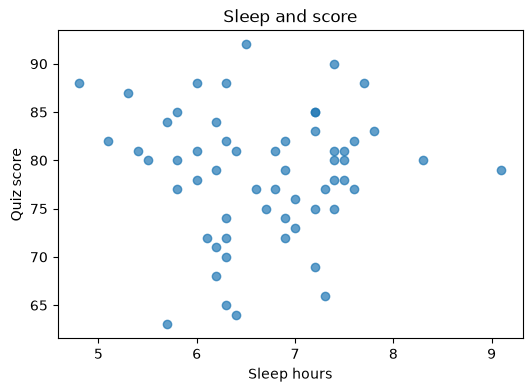

有效筆數： 58
相關係數： -0.015255866695473633


In [9]:
# 建立睡眠／分數有效配對並畫圖；不填補缺失資料
sleep_pairs = df.dropna(subset=["sleep_hours", "quiz_score"])
plt.figure(figsize=(6,4))
plt.scatter(sleep_pairs["sleep_hours"], sleep_pairs["quiz_score"], alpha=0.7)
plt.xlabel("Sleep hours"); plt.ylabel("Quiz score"); plt.title("Sleep and score"); plt.show()
print("有效筆數：", len(sleep_pairs))
print("相關係數：", sleep_pairs["sleep_hours"].corr(sleep_pairs["quiz_score"]))


## 本單元學習收束與 AI 使用紀錄

請學生先用自己的話解釋一個關鍵觀念，再指出一個執行結果及驗證方式。記錄：使用的提示詞、AI 回答中檢查或修改的地方、遇到的問題、修正後的證據與本資料限制。

回答：在任務六中，我了解到相關係數不是用「收了多少份問卷」算出來的，而是用「睡眠有填、成績也有填的那幾列」算出來的，也就是有效數據的重要，所以在做分析時要先檢查缺失值才能算出更準確的R值及各種圖表。

**通用提示詞**：我是 Python 初學者，請逐步協助我完成上面的任務；每段程式加繁體中文註解，說明輸入、處理與輸出，提供兩項可實際執行的驗證，保留原始資料，不要虛構執行結果。
